# Rush 4 — Segmentation des utilisateurs d'Instagram : usage et bien-être

## Introduction

### La demande
Le département Innovation d'Instagram nous demande de **livrer une segmentation des utilisateurs** qui :
- **repose sur leur usage** de l'application ;
- **explique le lien entre l'usage et le bien-être** ;
- est **utilisable par les équipes produit** ;
- est **défendue devant un jury**.

### Le contexte
Les réseaux sociaux doivent prouver qu'ils ne nuisent pas à leurs utilisateurs : les régulateurs posent des questions, la presse publie des études et les annonceurs ne veulent pas être associés à une plateforme qui rend les gens malheureux. Instagram veut **sa propre réponse, fondée sur ses propres données**.

Les données de **bien-être et de santé** (stress, bonheur, sommeil…) viennent d'un **panel de volontaires** qui ont accepté une étude bien-être. Les données d'**usage** (temps passé, sessions, likes…) et de **profil** (âge, pays…) existent, elles, pour **tous** les utilisateurs.

Nous ne travaillons pas sur de vrais utilisateurs mais sur une **réplique synthétique** du panel, fournie par l'équipe vie privée. Nos recommandations, elles, s'appliqueront à de vrais utilisateurs.

### Les données utilisées
- Fichier analysé : `data/instagram_usage_lifestyleSafe.csv` (200 000 utilisateurs, 58 colonnes).
- Fichier de comparaison : `data/instagram_users_lifestyleSafe.csv`, la seconde version de la réplique, utilisée seulement pour justifier notre choix (partie 0.2).
- Indicateurs de bien-être étudiés :
  - le **stress perçu** (`perceived_stress_score`, de 0 à 40). C'est la plage de l'échelle **PSS-10**, sans que la documentation le confirme. On considère le stress comme **élevé à partir de 27**, une convention de lecture courante et non un seuil de diagnostic ;
  - le **bonheur déclaré** (`self_reported_happiness`, de 1 à 10).

### Les règles suivies
- **Aucune donnée individuelle n'est affichée** : seulement des moyennes de groupes, et jamais un groupe de **moins de 100 utilisateurs**.
- **Résultats identiques à chaque exécution** : aucun tirage aléatoire.
- **Ce sont des corrélations**, pas des preuves de cause à effet.

### Le plan
0. **Préparation et choix des données** : quel fichier croire, et pourquoi, et les variables que nous construisons.
1. **Les pistes explorées sans lien** : le sommeil et l'activité physique.
2. **Le temps passé sur Instagram** : son lien avec le stress, puis avec le bonheur.
3. **Le rôle de l'âge** : qui est le plus stressé à usage égal, et qui est le plus exposé.
4. **Stress et bonheur** : deux indicateurs à suivre séparément.
5. **La segmentation** : le choix de la méthode, la carte des segments, nos critères et les quatre profils de bien-être.
6. **La protection des données.**
7. **Les limites** : ce que les données ne permettent pas d'affirmer.
8. **La conclusion générale**, avec trois recommandations pour les équipes produit.

## 0. Préparation

### 0.1 Bibliothèques, chargement des données et outils de calcul

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgba
from matplotlib.ticker import FuncFormatter
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# Couleurs (palette vérifiée pour les daltonismes les plus courants)
SURFACE = "#fcfcfb"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLEU, ORANGE = "#2a78d6", "#eb6834"
RAMPE_4 = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]   # 4 niveaux ordonnés, du plus clair au plus foncé
CMAP_SEQ = LinearSegmentedColormap.from_list(
    "bleu", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "figure.figsize": (9, 4.6),
    "font.family": "sans-serif", "font.size": 10.5,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "legend.fontsize": 9.5,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
})


def fr(valeur, decimales=1):
    """Écrit un nombre à la française : virgule décimale, espace pour les milliers."""
    if pd.isna(valeur):
        return "—"
    if round(valeur, decimales) == 0:
        valeur = 0.0
    return f"{valeur:,.{decimales}f}".replace(",", " ").replace(".", ",")


def afficher(table, decimales=1):
    """Affiche un tableau agrégé avec des nombres au format français."""
    def formater(v):
        if isinstance(v, (bool, np.bool_)):
            return v
        if isinstance(v, (int, np.integer)):
            return fr(v, 0)
        if isinstance(v, (float, np.floating)):
            return fr(v, decimales)
        return v
    display(table.apply(lambda colonne: colonne.map(formater)))


def titrer(ax, titre, sous_titre=None):
    """Titre en gras et sous-titre gris au-dessus d'un graphique."""
    ax.set_title(titre, loc="left", pad=26 if sous_titre else 10)
    if sous_titre:
        ax.text(0, 1.02, sous_titre, transform=ax.transAxes, fontsize=9.5, color=INK2, ha="left", va="bottom")


def titrer_figure(fig, titre, sous_titre=None):
    """Titre et sous-titre d'une figure à plusieurs panneaux (à appeler après tight_layout)."""
    if sous_titre:
        fig.text(0.01, 1.0, sous_titre, ha="left", va="bottom", fontsize=9.5, color=INK2)
    fig.text(0.01, 1.0 + (0.28 / fig.get_figheight() if sous_titre else 0), titre, ha="left", va="bottom",
             fontsize=12.5, fontweight="semibold", color=INK)


def barres(ax, valeurs, etiquettes, couleur=BLEU, decimales=1, suffixe=""):
    """Barres verticales avec la valeur écrite au-dessus de chaque barre."""
    positions = np.arange(len(valeurs))
    ax.bar(positions, valeurs, width=0.55, color=couleur)
    for p, v in zip(positions, valeurs):
        ax.text(p, v + max(valeurs) * 0.015, fr(v, decimales) + suffixe, ha="center", va="bottom", fontsize=9.5, color=INK)
    ax.set_xticks(positions, etiquettes)
    ax.grid(axis="x", visible=False)


FORMAT_HEURES = FuncFormatter(lambda v, _: f"{int(v)} h" if float(v).is_integer() else "")
FORMAT_POURCENT = FuncFormatter(lambda v, _: f"{v:.0f} %")

In [2]:
CANDIDATS = [Path("data/instagram_usage_lifestyleSafe.csv"),
             Path("../data/instagram_usage_lifestyleSafe.csv"),
             Path("instagram_usage_lifestyleSafe.csv")]
CHEMIN = next((p for p in CANDIDATS if p.exists()), None)
assert CHEMIN is not None, "Fichier introuvable : placez le notebook à côté du dossier data/."
df = pd.read_csv(CHEMIN)
N_COLONNES = df.shape[1]

STRESS = "perceived_stress_score"
BONHEUR = "self_reported_happiness"
TEMPS = "daily_active_minutes_instagram"
MIN_N = 100  # taille minimale d'un groupe affiché

CAT_TEMPS = ["< 1 h", "1–2 h", "2–3 h", "3–4 h", "4–5 h", "5 h et +"]
TRANCHES_AGE = ["13–17 ans", "18–24 ans", "25–34 ans", "35–44 ans", "45–54 ans", "55–65 ans"]

df["heures"] = df[TEMPS] / 60
df["tranche_10min"] = (df[TEMPS] // 10).astype(int)
df["tranche_30min"] = ((df[TEMPS] // 30) * 30).astype(int)
df["cat_temps"] = pd.cut(df[TEMPS], [0, 60, 120, 180, 240, 300, np.inf], right=False, labels=CAT_TEMPS)
df["tranche_age"] = pd.cut(df["age"], [13, 18, 25, 35, 45, 55, 66], right=False, labels=TRANCHES_AGE)
df["stress_eleve"] = df[STRESS] >= 27
df["tres_heureux"] = df[BONHEUR] >= 9
df["tres_malheureux"] = df[BONHEUR] <= 2


def agreger(data, cles, **mesures):
    """Moyennes par groupe ; les groupes de moins de MIN_N utilisateurs sont retirés."""
    table = data.groupby(cles, observed=True).agg(n=(STRESS, "size"), **mesures)
    return table[table["n"] >= MIN_N]


def part_expliquee(data, y, cles):
    """Part des écarts de y entre utilisateurs expliquée par les groupes (de 0 à 1)."""
    moyenne_groupe = data.groupby(cles, observed=True)[y].transform("mean")
    return 1 - ((data[y] - moyenne_groupe) ** 2).sum() / ((data[y] - data[y].mean()) ** 2).sum()


print(f"{fr(len(df), 0)} utilisateurs, {N_COLONNES} colonnes, {int(df.isna().sum().sum())} valeur manquante")

200 000 utilisateurs, 58 colonnes, 0 valeur manquante


### 0.2 Quel fichier croire, et sur quels champs ?

Instagram nous a envoyé **deux versions** de la réplique. L'une a subi un nettoyage que l'équipe vie privée n'a pas documenté, et les deux ne concordent pas entièrement. La consigne nous demande de décider laquelle croire, champ par champ, et de documenter ce choix.

In [3]:
AUTRE = CHEMIN.with_name("instagram_users_lifestyleSafe.csv")
if AUTRE.exists():
    autre = pd.read_csv(AUTRE)
    meme_ordre = df["user_id"].equals(autre["user_id"])
    colonnes_origine = list(autre.columns)
    differences = pd.Series({
        c: int((df[c].astype(str) != autre[c].astype(str)).sum()) for c in colonnes_origine
    })
    differences = differences[differences > 0]
    print(f"Mêmes utilisateurs dans le même ordre : {meme_ordre}")
    print(f"Colonnes identiques dans les deux fichiers : {len(colonnes_origine) - len(differences)} sur {len(colonnes_origine)}")
    print("Colonnes qui diffèrent (nombre de lignes concernées) :")
    afficher(differences.rename("lignes différentes").to_frame().rename_axis("colonne"))

    mineurs = df["age"] < 18
    comparaison = pd.DataFrame({
        "fichier usage (analysé)": {
            "part déclarée salariée à temps plein (%)": (df.loc[mineurs, "employment_status"] == "Full-time employed").mean() * 100,
            "heures de travail par semaine (moyenne)": df.loc[mineurs, "weekly_work_hours"].mean(),
        },
        "fichier users (autre version)": {
            "part déclarée salariée à temps plein (%)": (autre.loc[mineurs, "employment_status"] == "Full-time employed").mean() * 100,
            "heures de travail par semaine (moyenne)": autre.loc[mineurs, "weekly_work_hours"].mean(),
        },
    })
    print(f"Les 13–17 ans ({fr(mineurs.sum(), 0)} utilisateurs) dans les deux fichiers :")
    afficher(comparaison)
    lignes_mineurs = (df.loc[mineurs, "employment_status"] != autre.loc[mineurs, "employment_status"]).sum()
    print(f"Lignes d'emploi différentes chez les 13–17 ans : {fr(lignes_mineurs, 0)} sur "
          f"{fr(differences.get('employment_status', 0), 0)} au total")
    COLONNES_UTILISEES = [STRESS, BONHEUR, TEMPS, "age", "sleep_hours_per_night", "daily_steps_count",
                          "exercise_hours_per_week", "sessions_per_day", "average_session_length_minutes"]
    identiques = all(df[c].astype(str).equals(autre[c].astype(str)) for c in COLONNES_UTILISEES)
    print(f"Les {len(COLONNES_UTILISEES)} colonnes utilisées dans ce notebook sont identiques dans les deux fichiers : {identiques}")
    del autre
else:
    print("Fichier de comparaison absent : la comparaison n'est pas recalculée.")

Mêmes utilisateurs dans le même ordre : True
Colonnes identiques dans les deux fichiers : 52 sur 58
Colonnes qui diffèrent (nombre de lignes concernées) :


,lignes différentes
colonne,
employment_status,18 913
education_level,1 203
relationship_status,6 623
has_children,5 329
weekly_work_hours,18 912
account_creation_year,31 772


Les 13–17 ans (18 913 utilisateurs) dans les deux fichiers :


,fichier usage (analysé),fichier users (autre version)
part déclarée salariée à temps plein (%),"45,4","0,0"
heures de travail par semaine (moyenne),"40,0","0,0"


Lignes d'emploi différentes chez les 13–17 ans : 18 913 sur 18 913 au total


Les 9 colonnes utilisées dans ce notebook sont identiques dans les deux fichiers : True


**Ce que montre la comparaison**
- Les deux fichiers contiennent les **mêmes utilisateurs**, et **52 colonnes sur 58 sont identiques**.
- Les écarts portent sur la situation d'emploi, les heures de travail, le niveau d'études, la situation de couple, les enfants et l'année de création du compte.
- **L'écart le plus net concerne les mineurs.** Dans le fichier `usage`, 45 % des 13–17 ans sont déclarés salariés à temps plein, avec 40 h de travail par semaine en moyenne, ce qui est incohérent. Dans le fichier `users`, ces mêmes lignes sont corrigées : aucun emploi, 0 h de travail. **Toutes** les différences sur l'emploi (18 913 lignes) concernent les mineurs.

**Notre décision**
- **Toutes les colonnes que nous utilisons** (stress, bonheur, temps passé, âge, sessions, sommeil, pas, sport) sont **identiques dans les deux fichiers** : nos résultats ne dépendent donc pas de ce choix.
- **Pour l'emploi et les heures de travail**, nous faisons confiance au fichier `users`, qui a corrigé l'incohérence des mineurs. Nous n'utilisons de toute façon pas ces colonnes.
- Les autres écarts (études, couple, enfants, année de création) ne peuvent pas être départagés sans la documentation du nettoyage. Ces colonnes ne servent pas à notre segmentation.

> **Ce qu'on retient :** nous travaillons sur le fichier `usage`, et ce choix est sans risque : les colonnes utilisées sont strictement les mêmes dans les deux versions.

### 0.3 Les variables construites, et ce qu'elles apportent

La consigne demande que chaque variable construite soit **justifiée par ce qu'elle apporte sur les données**. Nous en construisons trois, et nous en avons testé d'autres que nous n'avons pas gardées.
- **Six catégories de temps passé** (moins d'1 h, 1–2 h… 5 h et plus) : des paliers d'une heure, lisibles par les équipes produit.
- **Quatre groupes d'âge** (13–17, 18–34, 35–54, 55–65 ans) : les mineurs à part pour des raisons légales, et trois groupes d'adultes.
- **Un indicateur « stress élevé »** (27 ou plus sur 40) : la borne haute de la convention de lecture de l'échelle PSS-10 (faible 0–13, modéré 14–26, élevé 27–40).

In [4]:
def part_expliquee_par(*colonnes):
    return part_expliquee(df, STRESS, list(colonnes))

groupe_4 = pd.cut(df["age"], [13, 18, 35, 55, 66], right=False,
                  labels=["13–17 ans", "18–34 ans", "35–54 ans", "55–65 ans"]).rename("groupe_4")
df["_groupe_4"] = groupe_4
apport = pd.DataFrame({
    "part du stress expliquée (%)": [
        part_expliquee_par("tranche_10min") * 100,
        part_expliquee_par("cat_temps") * 100,
        part_expliquee_par("cat_temps", "_groupe_4") * 100,
        part_expliquee_par("cat_temps", "tranche_age") * 100,
    ]
}, index=["temps passé, par tranches de 10 min (référence)",
          "6 catégories de temps passé",
          "6 catégories de temps × 4 groupes d'âge (nos segments)",
          "6 catégories de temps × 6 tranches d'âge"])
print("Ce que chaque découpage apporte :")
afficher(apport)

niveaux = pd.cut(df[STRESS], [-1, 13, 26, 40], labels=["faible (0–13)", "modéré (14–26)", "élevé (27–40)"])
print("Répartition des utilisateurs par niveau de stress (%) :")
afficher(niveaux.value_counts(normalize=True).mul(100).sort_index().to_frame("part (%)").rename_axis("niveau"))


def lien_a_temps_egal(colonne):
    rx, ry = df[colonne].rank(pct=True), df[STRESS].rank(pct=True)
    rx = rx - rx.groupby(df["tranche_10min"]).transform("mean")
    ry = ry - ry.groupby(df["tranche_10min"]).transform("mean")
    return float(np.corrcoef(rx, ry)[0, 1])


temps_parties = df[["time_on_feed_per_day", "time_on_reels_per_day", "time_on_explore_per_day", "time_on_messages_per_day"]]
df["_part_passive"] = (temps_parties.iloc[:, :3].sum(axis=1) / temps_parties.sum(axis=1)).fillna(0)
df["_interactions_par_minute"] = (df["likes_given_per_day"] + df["comments_written_per_day"]) / df[TEMPS]
df["_ratio_abonnements"] = df["following_count"] / df["followers_count"]
non_gardees = pd.Series({
    "part du temps passée à regarder sans interagir": lien_a_temps_egal("_part_passive"),
    "likes et commentaires par minute": lien_a_temps_egal("_interactions_par_minute"),
    "ratio abonnements / abonnés": lien_a_temps_egal("_ratio_abonnements"),
}, name="lien avec le stress à temps égal (−1 à 1)")
print("Variables construites puis écartées :")
afficher(non_gardees.to_frame(), decimales=3)
df = df.drop(columns=["_groupe_4", "_part_passive", "_interactions_par_minute", "_ratio_abonnements"])

Ce que chaque découpage apporte :


,part du stress expliquée (%)
"temps passé, par tranches de 10 min (référence)","70,7"
6 catégories de temps passé,"68,7"
6 catégories de temps × 4 groupes d'âge (nos segments),"71,1"
6 catégories de temps × 6 tranches d'âge,"71,3"


Répartition des utilisateurs par niveau de stress (%) :


,part (%)
niveau,
faible (0–13),"34,1"
modéré (14–26),"31,7"
élevé (27–40),"34,2"


Variables construites puis écartées :


,lien avec le stress à temps égal (−1 à 1)
part du temps passée à regarder sans interagir,"-0,002"
likes et commentaires par minute,"0,000"
ratio abonnements / abonnés,"0,003"


**Ce que montrent les données**
- **Les six catégories de temps** expliquent presque autant le stress (**69 %**) que le temps mesuré à 10 minutes près (**71 %**) : regrouper par heure ne fait presque rien perdre, et rend les segments lisibles.
- **Les quatre groupes d'âge** ajoutent environ **2 points** d'explication (**71 %**), autant que six tranches d'âge plus fines (**71 %**). Le découpage le plus simple suffit, et il isole les mineurs, ce qu'impose la loi. L'âge pèse peu dans la moyenne, mais beaucoup sur la part de stress élevé à temps égal (jusqu'à 34 points d'écart, voir les critères de la partie 5).
- **Le seuil de stress élevé** sépare un tiers des utilisateurs (**34 %**) : un groupe assez grand pour être suivi, et qui correspond à une convention connue, sans être un seuil de diagnostic.
- **Les autres variables testées** (part d'usage passif, interactions par minute, ratio abonnements/abonnés) n'ont **aucun lien avec le stress à temps égal** : nous ne les avons pas gardées.

> **Ce qu'on retient :** chaque variable gardée apporte quelque chose de mesurable, et celles qui n'apportaient rien ont été écartées.

---
## 1. Les pistes explorées sans lien

Nous sommes partis de deux idées appuyées par des sources de santé publique : Instagram pourrait réduire le **sommeil** ou l'**activité physique**, deux facteurs connus du bien-être. **Dans notre panel, ni l'une ni l'autre ne se vérifie.** Nous les présentons quand même : un indicateur sans lien avec l'usage est aussi un résultat.

### Piste 1 — Le sommeil

**Questions :** Instagram fait-il baisser le nombre d'heures de sommeil de ses utilisateurs ? Le manque de sommeil joue-t-il un rôle dans le bien-être ?

**Source :** [info.gouv.fr, « Santé mentale : pourquoi le sommeil joue un rôle clé », 2025](https://www.info.gouv.fr/actualite/sante-mentale-pourquoi-le-sommeil-joue-un-role-cle) : « Avoir une bonne santé du sommeil contribue à avoir une bonne santé mentale. »

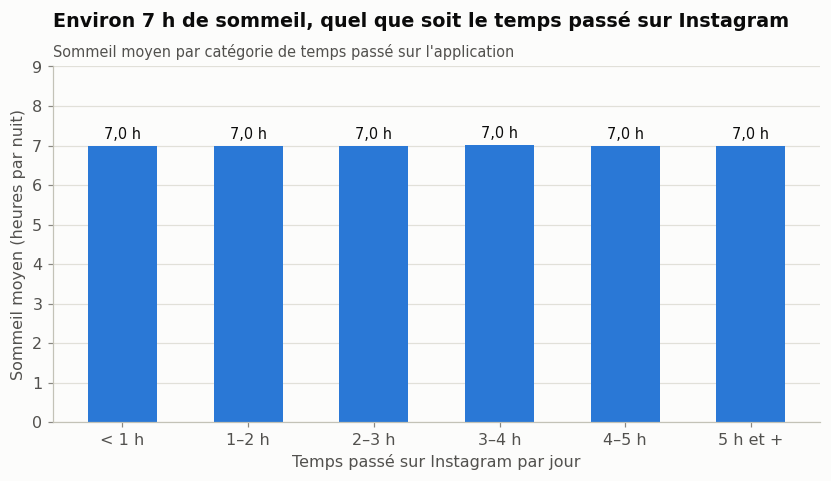

,n,sommeil_moyen,part_moins_de_6h
temps par jour,,,
< 1 h,29 197,"7,00","17,27"
1–2 h,30 541,"6,99","17,43"
2–3 h,35 721,"7,00","17,07"
3–4 h,36 144,"7,00","16,84"
4–5 h,32 566,"6,99","17,30"
5 h et +,35 831,"7,00","17,16"


Sommeil et stress : 0,000 · sommeil et bonheur : 0,003 (corrélations de −1 à 1, 0 = aucun lien)


In [5]:
sommeil = agreger(df, "cat_temps",
                  sommeil_moyen=("sleep_hours_per_night", "mean"),
                  part_moins_de_6h=("sleep_hours_per_night", lambda s: (s < 6).mean() * 100))

fig, ax = plt.subplots(figsize=(9, 4.2))
barres(ax, sommeil["sommeil_moyen"], CAT_TEMPS, decimales=1, suffixe=" h")
ax.set_ylim(0, 9)
ax.set_xlabel("Temps passé sur Instagram par jour")
ax.set_ylabel("Sommeil moyen (heures par nuit)")
titrer(ax, "Environ 7 h de sommeil, quel que soit le temps passé sur Instagram",
       "Sommeil moyen par catégorie de temps passé sur l'application")
plt.show()

afficher(sommeil.rename_axis("temps par jour"), decimales=2)
print(f"Sommeil et stress : {fr(df['sleep_hours_per_night'].corr(df[STRESS], method='spearman'), 3)} · "
      f"sommeil et bonheur : {fr(df['sleep_hours_per_night'].corr(df[BONHEUR], method='spearman'), 3)} "
      "(corrélations de −1 à 1, 0 = aucun lien)")

**Ce que montrent les données**
- Le sommeil moyen est d'environ **7 h** dans toutes les catégories, de moins d'1 h à plus de 5 h par jour sur Instagram.
- La part de petits dormeurs (moins de 6 h) est la même partout, autour de 17 %.
- Le sommeil n'est lié ni au stress ni au bonheur (corrélations proches de 0).

> **Ce qu'on retient :** dans notre panel, Instagram n'est pas associé à moins de sommeil, et le sommeil n'est pas associé au bien-être. **Pas de lien.**

### Piste 2 — L'activité physique (pas par jour et sport)

**Questions :** le temps passé sur Instagram fait-il baisser l'activité physique ? L'activité physique joue-t-elle un rôle sur le bien-être ?

**Source :** [Ameli, « Sport et activité physique : un atout pour le bien-être »](https://www.ameli.fr/assure/sante/themes/activite-physique-sante/sport-et-activite-physique-un-atout-pour-le-bien-etre). En résumé : l'activité physique réduit le stress et l'anxiété, régule l'humeur et améliore le sommeil.

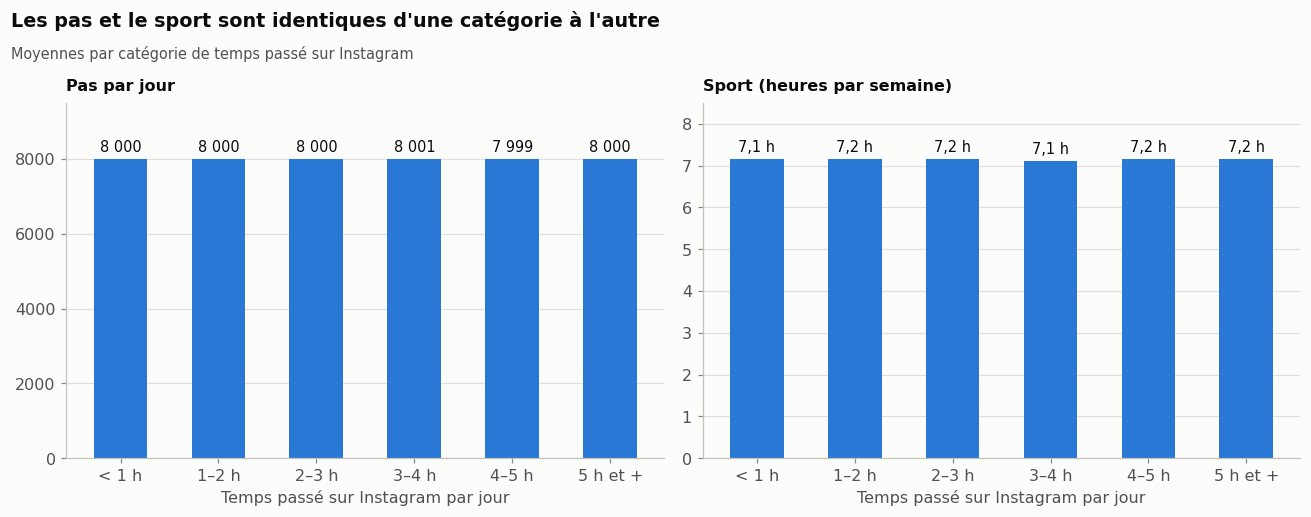

,n,pas_par_jour,sport_heures_semaine
temps par jour,,,
< 1 h,29 197,"8 000,3","7,1"
1–2 h,30 541,"7 999,9","7,2"
2–3 h,35 721,"8 000,2","7,2"
3–4 h,36 144,"8 001,0","7,1"
4–5 h,32 566,"7 999,1","7,2"
5 h et +,35 831,"8 000,1","7,2"


Pas et stress : -0,002 · pas et bonheur : -0,005
Sport et stress : -0,002 · sport et bonheur : -0,007
Pas par jour : 98 % des utilisateurs entre 7 794 et 8 208


In [6]:
activite = agreger(df, "cat_temps",
                   pas_par_jour=("daily_steps_count", "mean"),
                   sport_heures_semaine=("exercise_hours_per_week", "mean"))

fig, (ax_g, ax_d) = plt.subplots(1, 2, figsize=(12, 4.2))
barres(ax_g, activite["pas_par_jour"], CAT_TEMPS, decimales=0)
ax_g.set_ylim(0, 9500)
ax_g.set_title("Pas par jour", fontsize=10.5, loc="left", pad=8)
barres(ax_d, activite["sport_heures_semaine"], CAT_TEMPS, decimales=1, suffixe=" h")
ax_d.set_ylim(0, 8.5)
ax_d.set_title("Sport (heures par semaine)", fontsize=10.5, loc="left", pad=8)
for ax in (ax_g, ax_d):
    ax.set_xlabel("Temps passé sur Instagram par jour")
fig.tight_layout()
titrer_figure(fig, "Les pas et le sport sont identiques d'une catégorie à l'autre",
              "Moyennes par catégorie de temps passé sur Instagram")
plt.show()

afficher(activite.rename_axis("temps par jour"))
for colonne, nom in (("daily_steps_count", "Pas"), ("exercise_hours_per_week", "Sport")):
    print(f"{nom} et stress : {fr(df[colonne].corr(df[STRESS], method='spearman'), 3)} · "
          f"{nom.lower()} et bonheur : {fr(df[colonne].corr(df[BONHEUR], method='spearman'), 3)}")
print(f"Pas par jour : 98 % des utilisateurs entre {fr(df['daily_steps_count'].quantile(0.01), 0)} "
      f"et {fr(df['daily_steps_count'].quantile(0.99), 0)}")

**Ce que montrent les données**
- Environ **8 000 pas par jour** et **7,2 h de sport par semaine** dans toutes les catégories de temps passé.
- Ni les pas ni le sport ne sont liés au stress ou au bonheur (corrélations proches de 0).
- Le nombre de pas varie très peu d'un utilisateur à l'autre (98 % entre environ 7 800 et 8 200) : cette variable ne permet pas de distinguer des profils.

> **Ce qu'on retient :** dans notre panel, Instagram n'est pas associé à moins d'activité physique, et l'activité physique n'est pas associée au bien-être. **Pas de lien.** Nos sources laissaient attendre l'inverse : c'est une limite de la réplique synthétique, pas une preuve que le sport est sans effet.

---
## 2. Le temps passé sur Instagram : le cœur du lien

### Piste 1.1 — Le temps passé chaque jour est-il le facteur d'usage le plus lié au stress ?

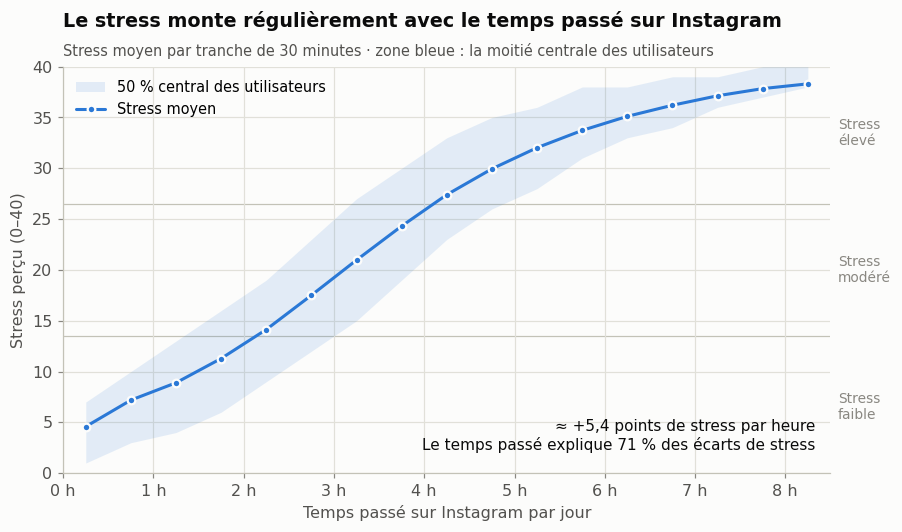

,n,stress_moyen
temps par jour,,
< 1 h,29 197,"5,6"
1–2 h,30 541,"10,2"
2–3 h,35 721,"15,8"
3–4 h,36 144,"22,6"
4–5 h,32 566,"28,6"
5 h et +,35 831,"33,9"


In [7]:
t11 = agreger(df, "tranche_30min",
              stress=(STRESS, "mean"),
              q1=(STRESS, lambda s: s.quantile(0.25)),
              q3=(STRESS, lambda s: s.quantile(0.75)))
x = (t11.index + 15) / 60
pente = np.polyfit(df["heures"], df[STRESS], 1)[0]
r2_stress = part_expliquee(df, STRESS, "tranche_10min")

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.fill_between(x, t11["q1"], t11["q3"], color=to_rgba(BLEU, 0.12), linewidth=0, label="50 % central des utilisateurs")
ax.plot(x, t11["stress"], color=BLEU, marker="o", markersize=5, markeredgecolor=SURFACE,
        markeredgewidth=1.5, label="Stress moyen")
for limite in (13.5, 26.5):
    ax.axhline(limite, color=AXIS, linewidth=0.8, zorder=0)
for y_texte, niveau in ((6.5, "faible"), (20, "modéré"), (33.5, "élevé")):
    ax.text(1.01, y_texte, f"Stress\n{niveau}", transform=ax.get_yaxis_transform(), color=MUTED, fontsize=9, va="center")
ax.set_xlim(0, x.max() + 0.25)
ax.set_ylim(0, 40)
ax.xaxis.set_major_formatter(FORMAT_HEURES)
ax.set_xlabel("Temps passé sur Instagram par jour")
ax.set_ylabel("Stress perçu (0–40)")
ax.legend(loc="upper left")
ax.text(0.98, 0.05, f"≈ +{fr(pente)} points de stress par heure\n"
        f"Le temps passé explique {fr(r2_stress * 100, 0)} % des écarts de stress",
        transform=ax.transAxes, ha="right", va="bottom", color=INK, fontsize=10)
titrer(ax, "Le stress monte régulièrement avec le temps passé sur Instagram",
       "Stress moyen par tranche de 30 minutes · zone bleue : la moitié centrale des utilisateurs")
plt.show()

afficher(agreger(df, "cat_temps", stress_moyen=(STRESS, "mean")).rename_axis("temps par jour"))

**Ce que montrent les données**
- Le stress moyen passe de **4,6** (moins de 30 min par jour) à **plus de 37** (7 h et plus).
- La hausse est **régulière** : environ **+5,4 points de stress par heure** passée sur Instagram.
- Le temps passé explique à lui seul **71 %** des écarts de stress entre utilisateurs.

| Temps par jour | < 1 h | 1–2 h | 2–3 h | 3–4 h | 4–5 h | 5 h et + |
|---|---|---|---|---|---|---|
| Stress moyen (sur 40) | 5,6 | 10,2 | 15,8 | 22,6 | 28,6 | 33,9 |

**Conclusion pour les équipes produit :** le temps quotidien passé sur l'application est **l'indicateur numéro un** à suivre pour repérer les groupes d'utilisateurs les plus stressés. Instagram le mesure déjà pour tous ses utilisateurs, sans rien leur demander.

**Sources externes :** [Riehm et al., 2019 (Johns Hopkins)](https://hub.jhu.edu/2019/09/11/social-media-teen-mental-health/) : au-delà de 3 h par jour de réseaux sociaux, le risque d'anxiété et de dépression des adolescents augmente. [Liu et al., 2022, méta-analyse](https://pmc.ncbi.nlm.nih.gov/articles/PMC9103874/) : chaque heure de plus par jour va avec environ 13 % de risque de dépression en plus.

> **Ce qu'on retient :** oui, **le temps passé est le facteur d'usage le plus lié au stress**. Plus on passe de temps sur Instagram, plus on est stressé, de façon régulière.

### Piste 1.2 — Le temps passé chaque jour est-il aussi lié au bonheur ?

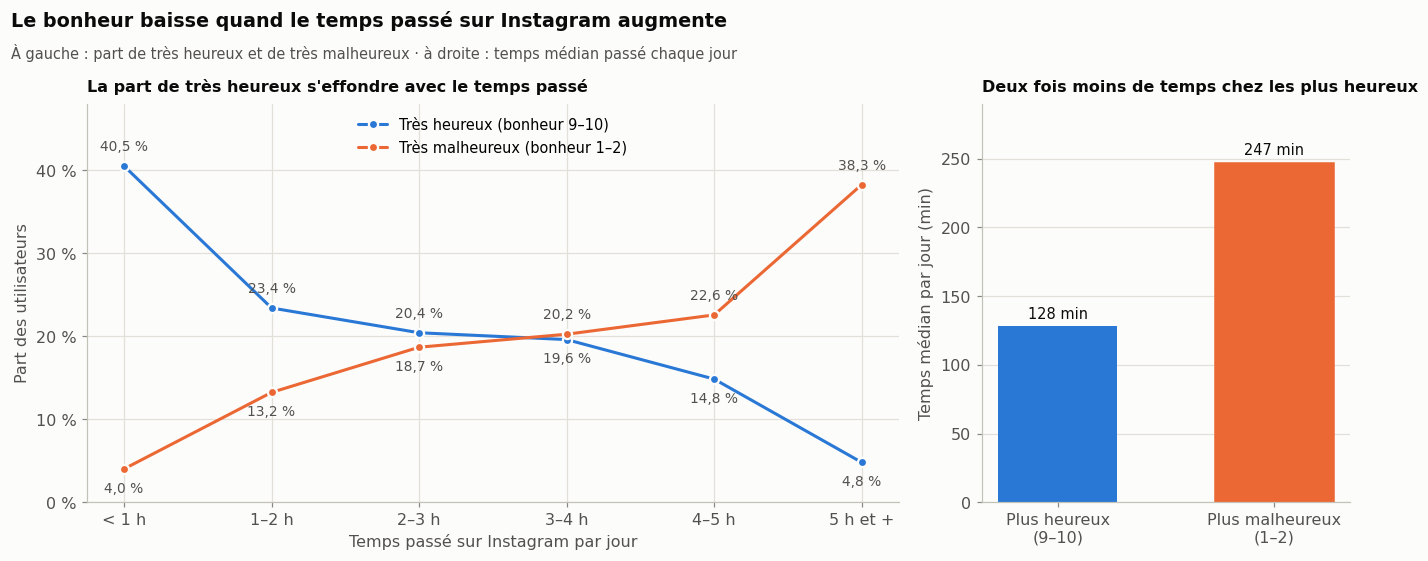

,n,part_tres_heureux,part_tres_malheureux
temps par jour,,,
< 1 h,29 197,"40,5","4,0"
1–2 h,30 541,"23,4","13,2"
2–3 h,35 721,"20,4","18,7"
3–4 h,36 144,"19,6","20,2"
4–5 h,32 566,"14,8","22,6"
5 h et +,35 831,"4,8","38,3"


,Plus heureux (9–10),Autres,Plus malheureux (1–2)
temps médian par jour (min),"128,0","202,0","247,0"
le quart qui y passe le moins : moins de (min),"44,0","118,0","164,0"
sessions par jour,"7,3","11,1","13,6"
durée d'une session (min),"18,9","20,9","21,4"


In [8]:
t12 = agreger(df, "cat_temps",
              part_tres_heureux=("tres_heureux", lambda s: s.mean() * 100),
              part_tres_malheureux=("tres_malheureux", lambda s: s.mean() * 100))

profils_temps = pd.DataFrame({
    groupe: {
        "temps médian par jour (min)": df.loc[masque, TEMPS].median(),
        "le quart qui y passe le moins : moins de (min)": df.loc[masque, TEMPS].quantile(0.25),
        "sessions par jour": df.loc[masque, "sessions_per_day"].mean(),
        "durée d'une session (min)": df.loc[masque, "average_session_length_minutes"].mean(),
    }
    for groupe, masque in (("Plus heureux (9–10)", df["tres_heureux"]),
                           ("Autres", ~df["tres_heureux"]),
                           ("Plus malheureux (1–2)", df["tres_malheureux"]))
})

fig, (ax_g, ax_d) = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [2.2, 1]})
positions = np.arange(len(t12))
heureux, malheureux = t12["part_tres_heureux"].to_numpy(), t12["part_tres_malheureux"].to_numpy()
for valeurs, autres, couleur, nom in ((heureux, malheureux, BLEU, "Très heureux (bonheur 9–10)"),
                                      (malheureux, heureux, ORANGE, "Très malheureux (bonheur 1–2)")):
    ax_g.plot(positions, valeurs, color=couleur, marker="o", markersize=6, markeredgecolor=SURFACE,
              markeredgewidth=1.5, label=nom)
    for p, v, w in zip(positions, valeurs, autres):
        au_dessus = v >= w  # la courbe la plus haute est étiquetée au-dessus, l'autre en dessous
        ax_g.text(p, v + (1.5 if au_dessus else -1.5), f"{fr(v)} %", ha="center",
                  va="bottom" if au_dessus else "top", fontsize=9, color=INK2)
ax_g.set_xticks(positions, CAT_TEMPS)
ax_g.set_ylim(0, 48)
ax_g.yaxis.set_major_formatter(FORMAT_POURCENT)
ax_g.set_xlabel("Temps passé sur Instagram par jour")
ax_g.set_ylabel("Part des utilisateurs")
ax_g.legend(loc="upper center")
ax_g.set_title("La part de très heureux s'effondre avec le temps passé", fontsize=10.5, loc="left", pad=8)

medianes = profils_temps.loc["temps médian par jour (min)", ["Plus heureux (9–10)", "Plus malheureux (1–2)"]]
barres(ax_d, medianes.to_numpy(), ["Plus heureux\n(9–10)", "Plus malheureux\n(1–2)"], decimales=0, suffixe=" min")
ax_d.patches[1].set_color(ORANGE)
ax_d.set_ylim(0, 290)
ax_d.set_ylabel("Temps médian par jour (min)")
ax_d.set_title("Deux fois moins de temps chez les plus heureux", fontsize=10.5, loc="left", pad=8)
fig.tight_layout()
titrer_figure(fig, "Le bonheur baisse quand le temps passé sur Instagram augmente",
              "À gauche : part de très heureux et de très malheureux · à droite : temps médian passé chaque jour")
plt.show()

afficher(t12.rename_axis("temps par jour"))
afficher(profils_temps)

**Ce que montrent les données**

Les plus heureux (bonheur de 9 ou 10, soit 20 % des utilisateurs) passent **beaucoup moins de temps** sur Instagram :

| | Plus heureux | Plus malheureux (bonheur de 1 ou 2) |
|---|---|---|
| Temps médian par jour | **128 min** | **247 min** |
| Le quart qui y passe le moins | moins de 44 min | moins de 164 min |

La part de très heureux **s'effondre** avec le temps passé :

| Temps par jour | < 1 h | 1–2 h | 2–3 h | 3–4 h | 4–5 h | 5 h et + |
|---|---|---|---|---|---|---|
| Très heureux (9–10) | 40,5 % | 23,4 % | 20,4 % | 19,6 % | 14,8 % | 4,8 % |
| Très malheureux (1–2) | 4,0 % | 13,2 % | 18,7 % | 20,2 % | 22,6 % | 38,3 % |

- Moins d'1 h par jour : **10 fois plus** de très heureux que de très malheureux.
- 5 h et plus : **8 fois plus** de très malheureux que de très heureux.

Les plus heureux **ouvrent aussi moins souvent l'application** : 7,3 sessions par jour contre 11,1 pour les autres, et des sessions un peu plus courtes (18,9 min contre 20,9).

> **Ce qu'on retient :** le temps passé est aussi lié au bonheur. **Les plus heureux sont ceux qui utilisent le moins Instagram**, en temps comme en nombre de sessions.

---
## 3. Le rôle de l'âge

### Piste 2 — D'après l'âge, à usage égal, qui est le plus stressé ?

Pour comparer des utilisateurs à **usage égal**, on regarde ceux qui passent **entre 3 et 4 h par jour** sur Instagram.

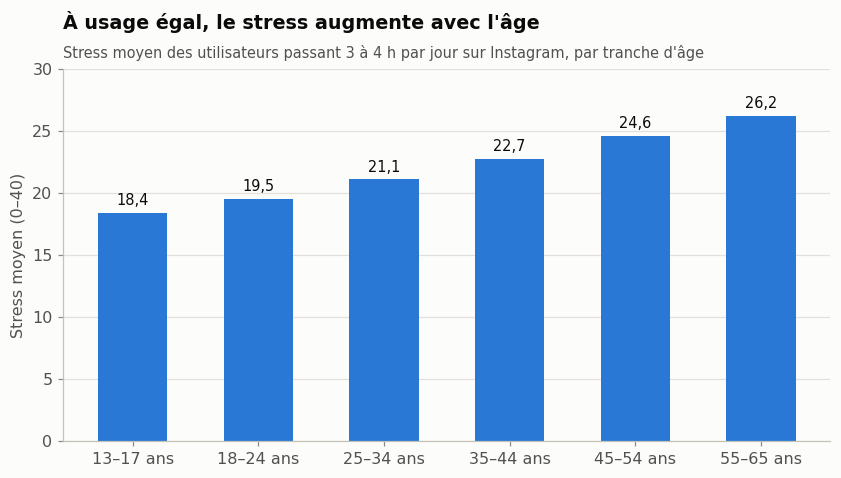

,n,minutes,stress
âge,,,
13–17 ans,3 413,"209,5","18,4"
18–24 ans,4 872,"209,4","19,5"
25–34 ans,6 913,"209,4","21,1"
35–44 ans,6 886,"209,2","22,7"
45–54 ans,6 758,"209,3","24,6"
55–65 ans,7 302,"209,0","26,2"


À temps égal, chaque tranche de 10 ans d'âge en plus va avec 1,2 point de stress en plus.

Stress moyen par âge et par temps passé (lire chaque colonne de haut en bas) :


temps par jour,< 1 h,1–2 h,2–3 h,3–4 h,4–5 h,5 h et +
âge,,,,,,
13–17 ans,"4,1","7,2","11,9","18,4","25,6","32,9"
18–24 ans,"4,5","8,0","12,9","19,5","26,3","33,0"
25–34 ans,"4,7","8,7","14,3","21,1","27,6","33,6"
35–44 ans,"5,3","10,0","15,7","22,7","28,9","34,2"
45–54 ans,"6,0","11,1","17,5","24,6","30,3","34,8"
55–65 ans,"6,5","12,7","19,5","26,2","31,3","35,3"


In [9]:
a_usage_egal = agreger(df[df["cat_temps"] == "3–4 h"], "tranche_age",
                       minutes=(TEMPS, "mean"), stress=(STRESS, "mean"))

fig, ax = plt.subplots(figsize=(9, 4.4))
barres(ax, a_usage_egal["stress"], a_usage_egal.index, decimales=1)
ax.set_ylim(0, 30)
ax.set_ylabel("Stress moyen (0–40)")
titrer(ax, "À usage égal, le stress augmente avec l'âge",
       "Stress moyen des utilisateurs passant 3 à 4 h par jour sur Instagram, par tranche d'âge")
plt.show()

afficher(a_usage_egal.rename_axis("âge"))

# Écart de stress à temps égal (tranches de 10 min), selon l'âge
ecart = df[STRESS] - df.groupby("tranche_10min")[STRESS].transform("mean")
print(f"À temps égal, chaque tranche de 10 ans d'âge en plus va avec "
      f"{fr(np.polyfit(df['age'], ecart, 1)[0] * 10, 1)} point de stress en plus.")
print("\nStress moyen par âge et par temps passé (lire chaque colonne de haut en bas) :")
afficher(agreger(df, ["tranche_age", "cat_temps"], stress=(STRESS, "mean"))["stress"]
         .unstack("cat_temps").rename_axis(index="âge", columns="temps par jour"))

**Ce que montrent les données** (utilisateurs passant 3 à 4 h par jour)

| Âge | 13–17 ans | 18–24 ans | 25–34 ans | 35–44 ans | 45–54 ans | 55–65 ans |
|---|---|---|---|---|---|---|
| Stress (sur 40) | 18,4 | 19,5 | 21,1 | 22,7 | 24,6 | 26,2 |

- À temps égal, le stress augmente de **+1,2 point par tranche de 10 ans**.
- Le même écart se retrouve dans toutes les catégories de temps passé (tableau complet ci-dessus).

> **Ce qu'on retient :** **à usage égal, ce sont les plus âgés qui sont les plus stressés.** Le temps passé ne suffit donc pas : l'âge apporte une information en plus.

### Piste 3 — Les plus jeunes passent-ils plus de temps sur Instagram ?

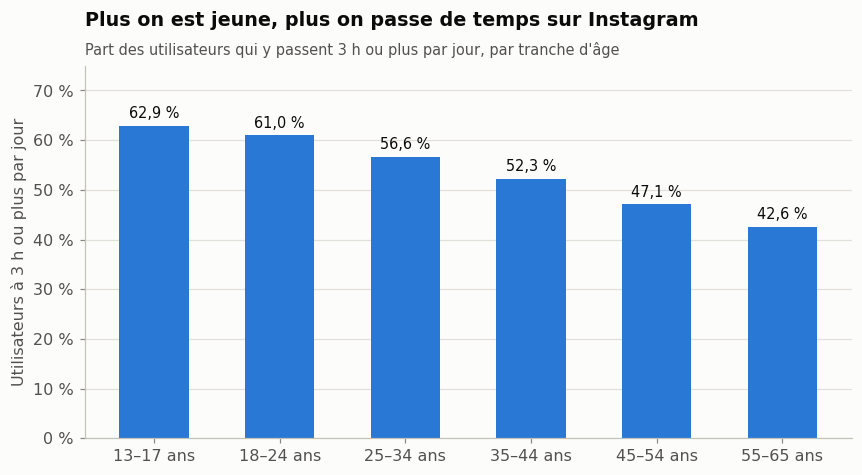

,n,minutes,part_3h_ou_plus
âge,,,
13–17 ans,18 913,"222,7","62,9"
18–24 ans,26 169,"215,1","61,0"
25–34 ans,38 097,"202,4","56,6"
35–44 ans,37 914,"188,1","52,3"
45–54 ans,37 652,"172,9","47,1"
55–65 ans,41 255,"158,8","42,6"


In [10]:
exposition = agreger(df, "tranche_age",
                     minutes=(TEMPS, "mean"),
                     part_3h_ou_plus=(TEMPS, lambda s: (s >= 180).mean() * 100))

fig, ax = plt.subplots(figsize=(9, 4.4))
barres(ax, exposition["part_3h_ou_plus"], exposition.index, decimales=1, suffixe=" %")
ax.set_ylim(0, 75)
ax.yaxis.set_major_formatter(FORMAT_POURCENT)
ax.set_ylabel("Utilisateurs à 3 h ou plus par jour")
titrer(ax, "Plus on est jeune, plus on passe de temps sur Instagram",
       "Part des utilisateurs qui y passent 3 h ou plus par jour, par tranche d'âge")
plt.show()

afficher(exposition.rename_axis("âge"))

**Ce que montrent les données**
- **63 %** des 13–17 ans passent 3 h ou plus par jour sur Instagram, contre **43 %** des 55–65 ans.
- Le temps moyen baisse régulièrement avec l'âge, de 223 minutes à 159 minutes par jour.

**Conclusion :** les plus jeunes sont **les plus exposés** en temps passé. Ce sont eux que les outils de limitation de temps touchent le plus souvent, et ils incluent des **mineurs**, qui demandent des précautions particulières (partie 6).

**Source :** [question écrite à l'Assemblée nationale citant le rapport « Enfants et écrans » (2024)](https://www.assemblee-nationale.fr/dyn/16/questions/QANR5L16QE18298.pdf). Chez les 16–19 ans, le temps d'écran dépasse les cinq heures. Les experts estiment que « les écrans ne sont pas à l'origine de troubles du neurodéveloppement », mais appellent à la « vigilance » pour « éviter l'amplification de symptômes ». Ils évoquent notamment la nocivité des réseaux sociaux, « facteur de risque » de dépression ou d'anxiété en cas de « vulnérabilité préexistante ».

> **Ce qu'on retient :** **oui, les plus jeunes passent plus de temps sur Instagram.** Avec la piste 2, cela donne deux effets opposés : les jeunes sont plus exposés en temps, les plus âgés sont plus stressés à temps égal.

---
## 4. Stress et bonheur

### Piste 4 — Le stress lié à l'usage s'accompagne-t-il d'une baisse de bonheur ?

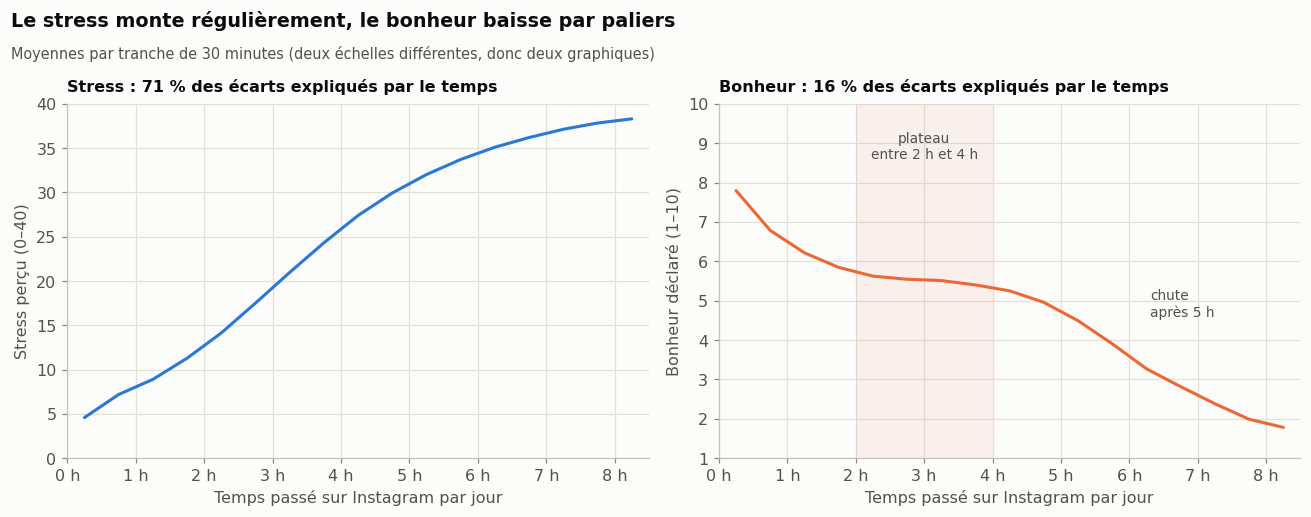

,n,stress,bonheur
temps par jour,,,
< 1 h,29 197,"5,6","7,4"
1–2 h,30 541,"10,2","6,0"
2–3 h,35 721,"15,8","5,6"
3–4 h,36 144,"22,6","5,5"
4–5 h,32 566,"28,6","5,1"
5 h et +,35 831,"33,9","3,8"


In [11]:
t4 = agreger(df, "tranche_30min", stress=(STRESS, "mean"), bonheur=(BONHEUR, "mean"))
x4 = (t4.index + 15) / 60
r2_bonheur = part_expliquee(df, BONHEUR, "tranche_10min")

fig, (ax_g, ax_d) = plt.subplots(1, 2, figsize=(12, 4.2))
ax_g.plot(x4, t4["stress"], color=BLEU)
ax_g.set_ylim(0, 40)
ax_g.set_ylabel("Stress perçu (0–40)")
ax_g.set_title(f"Stress : {fr(r2_stress * 100, 0)} % des écarts expliqués par le temps", fontsize=10.5, loc="left", pad=8)
ax_d.plot(x4, t4["bonheur"], color=ORANGE)
ax_d.set_ylim(1, 10)
ax_d.set_ylabel("Bonheur déclaré (1–10)")
ax_d.axvspan(2, 4, color=to_rgba(ORANGE, 0.08), linewidth=0)
ax_d.text(3, 8.6, "plateau\nentre 2 h et 4 h", ha="center", fontsize=9, color=INK2)
ax_d.text(6.3, 4.6, "chute\naprès 5 h", ha="left", fontsize=9, color=INK2)
ax_d.set_title(f"Bonheur : {fr(r2_bonheur * 100, 0)} % des écarts expliqués par le temps", fontsize=10.5, loc="left", pad=8)
for ax in (ax_g, ax_d):
    ax.set_xlim(0, 8.5)
    ax.xaxis.set_major_formatter(FORMAT_HEURES)
    ax.set_xlabel("Temps passé sur Instagram par jour")
fig.tight_layout()
titrer_figure(fig, "Le stress monte régulièrement, le bonheur baisse par paliers",
              "Moyennes par tranche de 30 minutes (deux échelles différentes, donc deux graphiques)")
plt.show()

afficher(agreger(df, "cat_temps", stress=(STRESS, "mean"), bonheur=(BONHEUR, "mean")).rename_axis("temps par jour"))

**Ce que montrent les données**
- Le **stress** monte **régulièrement** avec le temps passé.
- Le **bonheur**, lui, baisse surtout **dans la première heure**, reste **stable entre 2 h et 4 h**, puis **chute après 5 h**.
- Le temps passé explique **71 %** des écarts de stress, mais seulement **16 %** des écarts de bonheur.

**Conclusion :** il faut **suivre le stress et le bonheur séparément** : un utilisateur peut être très stressé et très heureux à la fois. Le lien principal d'Instagram est avec **le stress**, pas avec le bonheur en général.

**Source externe :** [le modèle « dual continua » de Keyes (Frontiers in Psychology, 2022)](https://www.frontiersin.org/articles/10.3389/fpsyg.2022.885278/full) : la santé mentale positive et la détresse sont deux dimensions distinctes, pas les deux bouts d'une même échelle.

> **Ce qu'on retient :** le stress lié à l'usage s'accompagne d'une baisse de bonheur, mais **beaucoup plus faible et moins régulière**. Stress et bonheur sont deux indicateurs différents.

---
## 5. La segmentation

Les pistes précédentes montrent que **deux informations suffisent** à construire des segments : le **temps passé par jour** et l'**âge**. Toutes deux sont connues pour **tous** les utilisateurs, pas seulement pour les membres du panel, et aucune n'est une donnée de santé.

### Pourquoi cette méthode ?

La consigne propose deux voies : **prédire un indicateur de bien-être** à partir de l'usage, ou **regrouper automatiquement** les utilisateurs en profils (*clustering*). Nous avons choisi la première, sous une forme simple : des **segments par paliers** de temps passé et d'âge, dont on mesure la part d'utilisateurs en stress élevé.

**Pourquoi pas un regroupement automatique ?**
- **Il retrouverait surtout le temps passé.** Presque toutes les variables d'usage (likes, stories, fil, Reels, messages, publicités) sont des copies du temps total, comme le montre le calcul ci-dessous. Un algorithme de regroupement découperait donc les utilisateurs selon le temps passé, sans rien apprendre de plus.
- **Ses groupes sont difficiles à expliquer** aux équipes produit et peuvent changer d'une exécution à l'autre.
- **Il ne vise pas le bien-être** : il regroupe des usages qui se ressemblent, pas des utilisateurs dont le stress diffère.
- **Certaines méthodes ne passent pas à 200 000 utilisateurs**, comme le signale la consigne.

**Pourquoi des segments par paliers répondent mieux à la question**
- Ils sont **construits pour séparer le stress** : c'est le critère qui a guidé le choix du temps passé et de l'âge.
- Ils sont **lisibles** : « 4–5 h par jour, 55–65 ans » se comprend sans explication.
- Ils sont **applicables à tous les utilisateurs** et **sans donnée de santé**.
- Ils sont **stables et reproductibles** : aucun tirage aléatoire (voir les critères plus bas).

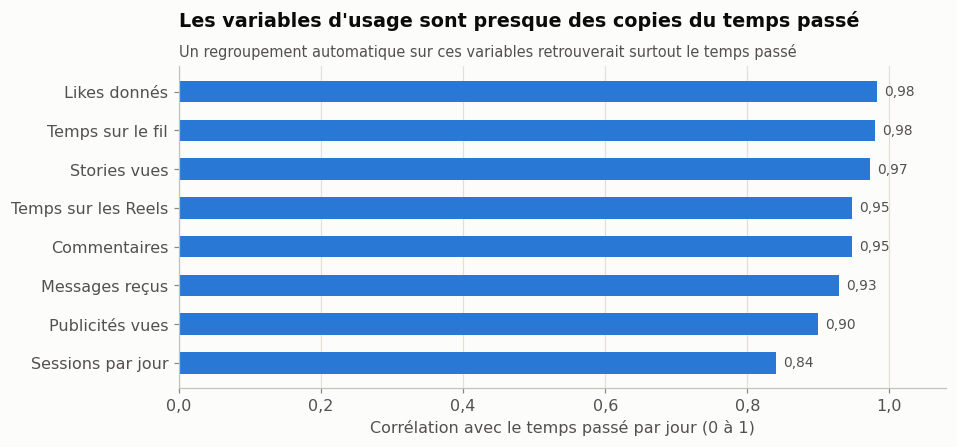

In [12]:
USAGE = {"likes_given_per_day": "Likes donnés", "stories_viewed_per_day": "Stories vues",
         "time_on_feed_per_day": "Temps sur le fil", "time_on_reels_per_day": "Temps sur les Reels",
         "comments_written_per_day": "Commentaires", "dms_received_per_week": "Messages reçus",
         "ads_viewed_per_day": "Publicités vues", "sessions_per_day": "Sessions par jour"}
copies = pd.Series({nom: df[col].corr(df[TEMPS], method="spearman") for col, nom in USAGE.items()}).sort_values()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(range(len(copies)), copies, height=0.55, color=BLEU)
for p, v in enumerate(copies):
    ax.text(v + 0.01, p, fr(v, 2), va="center", fontsize=9, color=INK2)
ax.set_yticks(range(len(copies)), copies.index)
ax.set_xlim(0, 1.08)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: fr(v, 1)))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Corrélation avec le temps passé par jour (0 à 1)")
titrer(ax, "Les variables d'usage sont presque des copies du temps passé",
       "Un regroupement automatique sur ces variables retrouverait surtout le temps passé")
plt.show()

> **Ce qu'on retient :** les variables d'usage disent presque toutes la même chose que le temps passé. Plutôt qu'un regroupement automatique difficile à expliquer, nous construisons des segments simples, choisis parce qu'ils séparent le stress.

### La carte des segments : part des utilisateurs en stress élevé

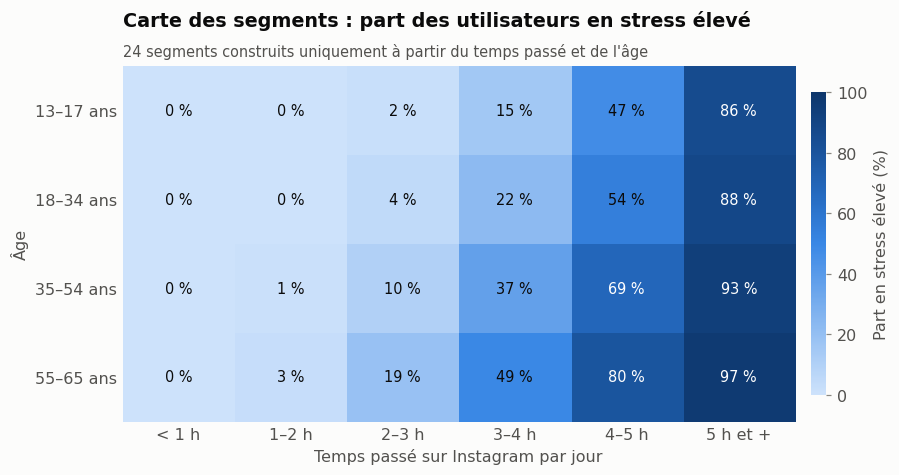

n stress part_stress_eleve
âge       temps par jour                                 
13–17 ans < 1 h            1 426    4,1               0,0
          1–2 h            2 375    7,2               0,0
          2–3 h            3 219   11,9               1,9
          3–4 h            3 413   18,4              15,1
          4–5 h            3 406   25,6              47,0
          5 h et +         5 074   32,9              85,6
18–34 ans < 1 h            6 513    4,6               0,0
          1–2 h            8 891    8,4               0,1
          2–3 h           11 327   13,7               4,3
          3–4 h           11 785   20,4              22,5
          4–5 h           11 217   27,1              54,2
          5 h et +        14 533   33,4              88,2
35–54 ans < 1 h           12 176    5,7               0,0
          1–2 h           12 145   10,6               1,0
          2–3 h           13 710   16,6               9,9
          3–4 h           13 644   23,7              36,7
          4–5 h           12 105   29,6              68,6
          5 h et +        11 786   34,5              93,4
55–65 ans < 1 h            9 082    6,5               0,1
          1–2 h            7 130   12,7               2,5
          2–3 h            7 465   19,5              18,6
          3–4 h            7 302   26,2              49,2
          4–5 h            5 838   31,3              79,5
          5 h et +         4 438   35,3              96,6

In [13]:
GROUPES_SEGMENT = ["13–17 ans", "18–34 ans", "35–54 ans", "55–65 ans"]   # les mineurs à part
BORNES_AGE_SEGMENT = [13, 18, 35, 55, 66]
BORNES_TEMPS = [0, 60, 120, 180, 240, 300, np.inf]
df["groupe_segment"] = pd.cut(df["age"], BORNES_AGE_SEGMENT, right=False, labels=GROUPES_SEGMENT)
segments = agreger(df, ["groupe_segment", "cat_temps"], stress=(STRESS, "mean"),
                   part_stress_eleve=("stress_eleve", lambda s: s.mean() * 100))
grille = segments["part_stress_eleve"].unstack("cat_temps").reindex(index=GROUPES_SEGMENT, columns=CAT_TEMPS)

fig, ax = plt.subplots(figsize=(9.5, 4.2))
palette = CMAP_SEQ.copy()
palette.set_bad(SURFACE)
image = ax.imshow(np.ma.masked_invalid(grille.to_numpy(dtype=float)), cmap=palette, vmin=0, vmax=100, aspect="auto")
for (i, j), v in np.ndenumerate(grille.to_numpy(dtype=float)):
    if not np.isnan(v):
        ax.text(j, i, f"{fr(v, 0)} %", ha="center", va="center", fontsize=9.5, color=INK if v < 55 else "white")
ax.set_xticks(range(len(CAT_TEMPS)), CAT_TEMPS)
ax.set_yticks(range(len(GROUPES_SEGMENT)), GROUPES_SEGMENT)
ax.grid(False)
ax.tick_params(length=0)
for cote in ax.spines.values():
    cote.set_visible(False)
barre = plt.colorbar(image, ax=ax, shrink=0.85, pad=0.02)
barre.set_label("Part en stress élevé (%)", color=INK2)
barre.outline.set_visible(False)
ax.set_xlabel("Temps passé sur Instagram par jour")
ax.set_ylabel("Âge")
titrer(ax, "Carte des segments : part des utilisateurs en stress élevé",
       "24 segments construits uniquement à partir du temps passé et de l'âge")
plt.show()

afficher(segments.rename_axis(["âge", "temps par jour"]))

**Affecter un nouvel utilisateur à un segment.** La fonction n'utilise que l'âge et le temps passé par jour. Les exemples sont des **utilisateurs fictifs**, pas des lignes du fichier.

In [14]:
def assigner_segment(age, minutes_par_jour):
    """Renvoie le segment d'un utilisateur à partir de son âge et de son temps quotidien sur Instagram."""
    if not 13 <= age <= 65:
        raise ValueError("L'âge doit être compris entre 13 et 65 ans (plage couverte par les données).")
    groupe = pd.cut([age], BORNES_AGE_SEGMENT, right=False, labels=GROUPES_SEGMENT)[0]
    categorie = pd.cut([minutes_par_jour], BORNES_TEMPS, right=False, labels=CAT_TEMPS)[0]
    profil = segments.loc[(groupe, categorie)]
    return {"segment": f"{groupe} · {categorie}",
            "part en stress élevé dans le segment (%)": float(profil["part_stress_eleve"]),
            "mineur": age < 18}


exemples = [(16, 250), (30, 250), (60, 250), (60, 90)]  # (âge, minutes par jour), utilisateurs fictifs
afficher(pd.DataFrame([{"âge": a, "minutes par jour": m, **assigner_segment(a, m)} for a, m in exemples]))

,âge,minutes par jour,segment,part en stress élevé dans le segment (%),mineur
0,16,250,13–17 ans · 4–5 h,"47,0",True
1,30,250,18–34 ans · 4–5 h,"54,2",False
2,60,250,55–65 ans · 4–5 h,"79,5",False
3,60,90,55–65 ans · 1–2 h,"2,5",False


**Ce que montre la carte**
- Les segments vont de **0 %** à **97 %** d'utilisateurs en stress élevé : ils séparent très nettement les situations.
- À temps égal, l'âge change fortement le résultat : entre 3 h et 4 h par jour, environ **15 %** de stress élevé chez les 13–17 ans contre **49 %** chez les 55–65 ans.

> **Ce qu'on retient :** une segmentation **simple** (temps passé × âge), **applicable à tous les utilisateurs** et **sans donnée de santé**, qui apporte plus qu'un simple classement par temps passé.

### Nos critères d'une bonne segmentation, et leur vérification

Personne ne nous a dit ce qu'est une bonne segmentation : nous fixons nos propres critères, tous **vérifiables sur les données**.
1. **Elle distingue bien le bien-être** : les segments doivent avoir des niveaux de stress très différents.
2. **Elle apporte plus que le temps passé seul** : à temps égal, les segments doivent encore différer.
3. **Elle s'applique à tout utilisateur** : avec des données connues pour tous, sans valeur manquante.
4. **Elle est stable** : recalculée sur deux moitiés du fichier, elle doit donner les mêmes résultats.
5. **Elle n'isole personne** : chaque segment compte au moins 100 utilisateurs.
6. **Elle n'utilise aucune donnée de santé.**

In [15]:
# 4. Stabilité : segments recalculés sur deux moitiés du fichier (identifiant pair / impair)
moitie = np.where(df["user_id"] % 2 == 0, "A", "B")
stabilite = (df.assign(moitie=moitie)
             .groupby(["moitie", "groupe_segment", "cat_temps"], observed=True)["stress_eleve"]
             .mean().mul(100).unstack("moitie"))
ecart_moities = (stabilite["A"] - stabilite["B"]).abs().max()

# 2. Apport au-delà du temps seul : plus grand écart entre groupes d'âge dans une même catégorie de temps
ecarts_age = grille.max() - grille.min()

criteres = pd.DataFrame([
    ("1. Distingue bien le bien-être", "part en stress élevé, du segment le plus bas au plus haut",
     f"de {fr(grille.min().min(), 0)} % à {fr(grille.max().max(), 0)} %"),
    ("2. Apporte plus que le temps seul", "plus grand écart entre groupes d'âge à temps égal",
     f"{fr(ecarts_age.max(), 0)} points (catégorie {ecarts_age.idxmax()})"),
    ("3. S'applique à tout utilisateur", "valeurs manquantes dans l'âge et le temps passé",
     f"{int(df[['age', TEMPS]].isna().sum().sum())}"),
    ("4. Est stable", "plus grand écart entre deux moitiés du fichier", f"{fr(ecart_moities, 1)} points"),
    ("5. N'isole personne", "plus petit segment",
     f"{fr(df.groupby(['groupe_segment', 'cat_temps'], observed=True).size().min(), 0)} utilisateurs"),
    ("6. Aucune donnée de santé", "variables utilisées", "âge et temps passé par jour"),
], columns=["critère", "mesure", "résultat"])
display(criteres)

,critère,mesure,résultat
0,1. Distingue bien le bien-être,"part en stress élevé, du segment le plus bas a...",de 0 % à 97 %
1,2. Apporte plus que le temps seul,plus grand écart entre groupes d'âge à temps égal,34 points (catégorie 3–4 h)
2,3. S'applique à tout utilisateur,valeurs manquantes dans l'âge et le temps passé,0
3,4. Est stable,plus grand écart entre deux moitiés du fichier,"2,0 points"
4,5. N'isole personne,plus petit segment,1 426 utilisateurs
5,6. Aucune donnée de santé,variables utilisées,âge et temps passé par jour


**Ce que montre la vérification**
- Les segments vont de **0 %** à **97 %** d'utilisateurs en stress élevé.
- À temps égal, l'âge fait varier la part en stress élevé de **34 points** (entre 3 h et 4 h par jour).
- Recalculés sur deux moitiés du fichier, les segments diffèrent de **2 points au maximum**.
- Le plus petit segment compte plus de **1 400 utilisateurs**.

> **Ce qu'on retient :** les six critères sont atteints. La segmentation est discriminante, utile au-delà du temps passé, applicable à tous, stable, sans risque d'isoler quelqu'un et sans donnée de santé.

### Piste 5 — Quatre profils de bien-être selon le temps passé

On croise le stress (élevé à partir de 27) et le bonheur (élevé à partir de 7).

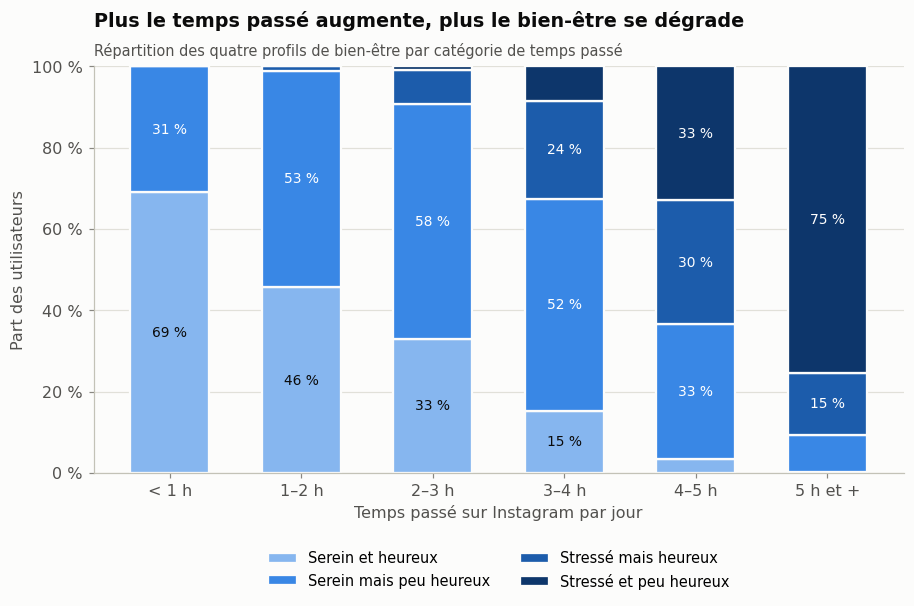

profil,Serein et heureux,Serein mais peu heureux,Stressé mais heureux,Stressé et peu heureux
temps par jour,,,,
< 1 h,"69,1","30,9","0,0","0,0"
1–2 h,"45,6","53,3","1,0","0,0"
2–3 h,"32,9","57,9","8,2","1,0"
3–4 h,"15,3","52,1","24,0","8,5"
4–5 h,"3,3","33,4","30,3","33,0"
5 h et +,"0,1","9,3","15,1","75,5"


In [16]:
PROFILS = ["Serein et heureux", "Serein mais peu heureux", "Stressé mais heureux", "Stressé et peu heureux"]
df["profil"] = np.select(
    [~df["stress_eleve"] & (df[BONHEUR] >= 7),
     ~df["stress_eleve"] & (df[BONHEUR] < 7),
     df["stress_eleve"] & (df[BONHEUR] >= 7)],
    PROFILS[:3], default=PROFILS[3])
parts = pd.crosstab(df["cat_temps"], df["profil"], normalize="index").mul(100)[PROFILS]

fig, ax = plt.subplots(figsize=(9.5, 4.8))
positions = np.arange(len(parts))
base = np.zeros(len(parts))
for couleur, profil in zip(RAMPE_4, PROFILS):
    ax.bar(positions, parts[profil], bottom=base, width=0.6, color=couleur, edgecolor=SURFACE, linewidth=1.5, label=profil)
    for p, b, v in zip(positions, base, parts[profil]):
        if v >= 12:
            ax.text(p, b + v / 2, f"{fr(v, 0)} %", ha="center", va="center", fontsize=9,
                    color=INK if couleur == RAMPE_4[0] else "white")
    base += parts[profil].to_numpy()
ax.set_xticks(positions, CAT_TEMPS)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(FORMAT_POURCENT)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Temps passé sur Instagram par jour")
ax.set_ylabel("Part des utilisateurs")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
titrer(ax, "Plus le temps passé augmente, plus le bien-être se dégrade",
       "Répartition des quatre profils de bien-être par catégorie de temps passé")
plt.show()

afficher(parts.rename_axis(index="temps par jour", columns="profil"))

**Ce que montrent les données**

| Temps par jour | Serein et heureux | Serein mais peu heureux | Stressé mais heureux | Stressé et peu heureux |
|---|---|---|---|---|
| < 1 h | 69 % | 31 % | 0 % | 0 % |
| 2–3 h | 33 % | 58 % | 8 % | 1 % |
| 4–5 h | 3 % | 33 % | 30 % | 33 % |
| 5 h et + | 0,1 % | 9 % | 15 % | 76 % |

- En dessous d'1 h par jour, **plus des deux tiers** des utilisateurs sont sereins et heureux.
- Au-delà de 5 h, **les trois quarts** sont stressés et peu heureux.
- Entre les deux, on passe d'abord par « serein mais peu heureux », puis par « stressé mais heureux ».

**Ce que ça apporte au produit :** ces profils décrivent **le parcours du bien-être selon la dose d'usage**. C'est plus parlant qu'un seul indicateur. Ils restent une lecture des résultats agrégés : **on ne les attribue pas à un utilisateur**, puisqu'ils reposent sur des données de santé du panel.

> **Ce qu'on retient :** plus la dose d'usage augmente, plus les utilisateurs glissent d'un profil serein et heureux vers un profil stressé et peu heureux.

---
## 6. Protection des données

La consigne nous demande de prendre position, pour les utilisateurs de l'Union européenne et du Royaume-Uni, y compris les moins de 18 ans, sur deux questions.

### Sur quelles variables les segments peuvent-ils reposer pour du ciblage ?
**Uniquement le temps passé par jour et l'âge.**
- Ce sont des données qu'Instagram détient **pour tous ses utilisateurs**, sans rien leur demander.
- Ce ne sont **pas des données de santé**.
- **Les variables de santé et de bien-être sont exclues** : stress, bonheur, sommeil, IMC, tension, tabac, alcool, alimentation, sport. Ce sont des données sensibles au sens de l'article 9 du RGPD ([CNIL](https://www.cnil.fr/fr/definition/donnee-sensible)). Elles n'ont été données qu'avec un consentement pour l'étude bien-être, pas pour du ciblage.
- **Les autres variables de profil sont exclues aussi** (genre, revenu, emploi, couple, enfants) : elles n'apportent rien à la segmentation, et le RGPD demande de ne traiter que les données nécessaires.

### Placer un utilisateur dans un segment peut-il révéler quelque chose sur sa santé ?
**Oui.** Même construits sans donnée de santé, certains segments laissent deviner un état de stress avec une forte probabilité (calcul ci-dessous). Une donnée qui révèle indirectement un état de santé doit être traitée comme une donnée de santé. D'où trois conditions :
- **nommer les segments par l'usage** (« 4–5 h par jour, 55–65 ans »), jamais par le stress attendu ;
- **ne stocker aucun score de stress** par utilisateur ;
- **réserver les segments aux outils de protection** (rappels de temps, mode sommeil), sans publicité.

In [17]:
segment_max = segments["part_stress_eleve"].idxmax()
print(f"Segment le plus révélateur : {segment_max[0]} · {segment_max[1]} par jour, "
      f"{fr(segments['part_stress_eleve'].max(), 0)} % de ses membres en stress élevé")
revelateurs = segments[segments["part_stress_eleve"] >= 80]
print(f"{len(revelateurs)} segments sur {len(segments)} comptent au moins 80 % d'utilisateurs en stress élevé "
      f"({fr(revelateurs['n'].sum() / len(df) * 100, 0)} % des utilisateurs).")

Segment le plus révélateur : 55–65 ans · 5 h et + par jour, 97 % de ses membres en stress élevé
4 segments sur 24 comptent au moins 80 % d'utilisateurs en stress élevé (18 % des utilisateurs).


### Les mineurs
- **Royaume-Uni :** le code de conception adapté à l'âge de l'ICO demande que **le profilage des enfants soit désactivé par défaut**, sauf raison impérieuse dans leur intérêt ([résumé par RPC](https://www.rpclegal.com/snapshots/data-protection/ico-age-appropriate-design-code-for-information-society-services/)).
- **Union européenne :** le règlement sur les services numériques (DSA, article 28) **interdit les publicités fondées sur le profilage** d'un utilisateur dont la plateforme sait qu'il est mineur ([EUR-Lex](https://eur-lex.europa.eu/eli/reg/2022/2065/oj)).

### Les mesures que nous appliquons et recommandons
- **Seuil de 100 utilisateurs :** aucune ligne individuelle ni aucun groupe de moins de 100 personnes n'est affiché dans ce notebook.
- **Données brutes hors du dépôt Git :** le dossier `data/` est ajouté au fichier `.gitignore`, pour que les CSV ne soient jamais publiés.
- **Une section « Limites et protection des données »** dans le notebook (parties 6 et 7) et dans le README.
- **Interdiction écrite** d'utiliser les segments pour la publicité ou de les transmettre aux annonceurs.
- **Informer les utilisateurs** du classement en segments, dans la politique de confidentialité.
- **Inscrire le traitement au registre des traitements**, en y précisant sa finalité, les données utilisées et la durée de conservation.

Rappel : le stress et le bonheur sont des **données de santé**, des données sensibles au sens de l'article 9 du RGPD ([CNIL](https://www.cnil.fr/fr/definition/donnee-sensible)). C'est pourquoi les segments reposent uniquement sur le temps passé et l'âge.

In [18]:
# Vérification de la règle des 100 utilisateurs sur les groupes utilisés dans le notebook
tailles = {
    "catégories de temps": df.groupby("cat_temps", observed=True).size().min(),
    "segments âge × temps": df.groupby(["groupe_segment", "cat_temps"], observed=True).size().min(),
    "âge × temps (tranches fines)": df.groupby(["tranche_age", "cat_temps"], observed=True).size().min(),
}
afficher(pd.Series(tailles, name="plus petit groupe (utilisateurs)").to_frame())

,plus petit groupe (utilisateurs)
catégories de temps,29 197
segments âge × temps,1 426
âge × temps (tranches fines),1 426


---
## 7. Limites

Ce que nos données **ne permettent pas d'affirmer**, et les points à garder en tête avant d'appliquer ces résultats à de vrais utilisateurs.

### 7.1 Pas de cause à effet
Tous nos liens sont des **corrélations**. On ne peut pas dire qu'Instagram *cause* le stress : les personnes stressées pourraient aussi passer plus de temps sur l'application. Seules des expériences, où l'on fait varier le temps passé, peuvent tester une cause.

### 7.2 Un panel de volontaires
Le stress et le bonheur ne sont mesurés que chez les **volontaires** de l'étude bien-être. Ils ne ressemblent pas forcément à l'ensemble des utilisateurs : on ne peut pas généraliser leur niveau de stress à tous.

### 7.3 Une réplique synthétique
Nos données sont **générées artificiellement**. Plusieurs signes montrent qu'elles ne reproduisent pas fidèlement la réalité :
- **le lien entre temps passé et stress est très fort** : 71 % des écarts expliqués, contre 0,4 % au maximum dans les études réelles ([Orben & Przybylski, 2019](https://www.oii.ox.ac.uk/technology-use-explains-at-most-0-4-of-adolescent-wellbeing/)) ;
- **des effets connus sont absents** : le sommeil et le sport, que nos sources associent au bien-être, n'ont aucun lien ici ;
- **un lien caché, très probablement artificiel, entre stress et bonheur** (calcul ci-dessous).

In [19]:
def residu(colonne):
    return df[colonne] - df.groupby("tranche_10min")[colonne].transform("mean")

global_ = df[STRESS].corr(df[BONHEUR])
a_temps_egal = np.corrcoef(residu(STRESS), residu(BONHEUR))[0, 1]
print(f"Corrélation stress ↔ bonheur, sur l'ensemble des utilisateurs : {fr(global_, 2)}")
print(f"Corrélation stress ↔ bonheur, à temps passé égal : {fr(a_temps_egal, 2)}")

niveau_bonheur = pd.cut(df[BONHEUR], [0, 2, 4, 6, 8, 10], labels=["1–2", "3–4", "5–6", "7–8", "9–10"])
exemple = agreger(df[df["cat_temps"] == "2–3 h"].assign(niveau_bonheur=niveau_bonheur), "niveau_bonheur",
                  stress_moyen=(STRESS, "mean"))
print("\nStress moyen selon le bonheur, chez les utilisateurs passant 2 à 3 h par jour :")
afficher(exemple.rename_axis("bonheur"))

Corrélation stress ↔ bonheur, sur l'ensemble des utilisateurs : 0,00
Corrélation stress ↔ bonheur, à temps passé égal : 0,60

Stress moyen selon le bonheur, chez les utilisateurs passant 2 à 3 h par jour :


,n,stress_moyen
bonheur,,
1–2,6 671,"9,0"
3–4,7 158,"11,9"
5–6,7 198,"15,6"
7–8,7 400,"19,1"
9–10,7 294,"22,9"


**Le lien caché entre stress et bonheur**
- Sur l'ensemble des utilisateurs, stress et bonheur **ne sont pas liés** (corrélation de 0,00).
- Mais **à temps passé égal**, ils sont **fortement liés, dans le même sens** (corrélation de **+0,60**) : entre 2 et 3 h par jour, le stress moyen passe d'environ 9 chez les moins heureux à environ 23 chez les plus heureux.
- Les deux effets s'annulent : plus de temps passé va avec plus de stress et moins de bonheur, mais à temps égal, les plus heureux sont aussi les plus stressés.
- **C'est très probablement un effet de la génération des données.** Dans la réalité, on s'attend plutôt à ce que les personnes stressées soient moins heureuses. Ce lien ne sert pas à la segmentation, et nous ne le transposons pas aux vrais utilisateurs.

### 7.4 D'autres points de prudence
- **Le seuil de stress élevé (27)** est une convention de lecture de l'échelle PSS-10, pas un seuil de diagnostic, et la documentation ne confirme pas qu'il s'agit bien de cette échelle.
- **Le choix du fichier** n'est sûr que pour les colonnes que nous utilisons : les autres écarts entre les deux versions (études, couple, enfants, année de création) ne peuvent pas être départagés sans la documentation du nettoyage.

> **Ce qu'on retient :** nos résultats décrivent **des tendances fortes dans une réplique synthétique**. Ils indiquent où regarder, mais doivent être **confirmés sur de vraies données** avant de servir de preuve, et ne permettent jamais de conclure à une cause.

---
## 8. Conclusion générale

**Le lien entre l'usage d'Instagram et le bien-être**
- **Le temps passé chaque jour est le facteur central.** Il explique **71 %** des écarts de stress (environ +5,4 points par heure) et **16 %** des écarts de bonheur. Les plus heureux passent deux fois moins de temps sur l'application que les plus malheureux (128 min contre 247 min).
- **L'âge change ce lien.** Les plus jeunes passent plus de temps sur Instagram, mais à temps égal, les plus âgés sont plus stressés (+1,2 point par tranche de 10 ans).
- **Le sommeil et l'activité physique ne sont pas liés à l'usage** dans notre panel.
- **Stress et bonheur sont deux indicateurs distincts**, à suivre séparément. Le lien principal d'Instagram est avec le stress.

**Une segmentation utilisable par les équipes produit**
- Deux informations suffisent, **le temps passé et l'âge**, connues pour tous les utilisateurs et sans donnée de santé.
- La carte des segments donne directement **les groupes à accompagner en priorité**, et un nouvel utilisateur peut y être placé avec la fonction `assigner_segment`.
- Les quatre profils de bien-être décrivent **le parcours du bien-être selon la dose d'usage**.
- Usage recommandé : des **outils de protection** (rappels de temps, mode sommeil), jamais de publicité, avec des règles renforcées pour les mineurs.

**Les limites** (partie 7) : des corrélations et non des causes, un panel de volontaires, et une réplique synthétique qui amplifie certains liens et en efface d'autres.

**Trois recommandations pour les équipes produit**
1. **Un rappel de temps quotidien cumulé, avec un seuil selon l'âge.** La carte des segments montre que le stress élevé apparaît plus tôt chez les plus âgés : environ 19 % des 55–65 ans sont déjà en stress élevé entre 2 h et 3 h par jour, contre 2 % des 13–17 ans. Nous recommandons un rappel vers **2 h par jour pour les 55–65 ans** et vers **3 h pour les 13–17 ans**, **activé par défaut pour les mineurs**. Le rappel doit compter le temps **de toute la journée**, pas seulement celui d'une session.
2. **Faire du temps quotidien passé l'indicateur de suivi numéro un**, par segment, dans les tableaux de bord produit. Et dans les futures études bien-être, **suivre le stress et le bonheur séparément** : ce sont deux indicateurs distincts.
3. **Réserver les segments aux outils de protection** (rappels, mode sommeil) : jamais de publicité, des segments nommés par l'usage et non par le stress, et une analyse d'impact sur la protection des données avant tout déploiement.

> **En une phrase :** plus on passe de temps sur Instagram, plus on est stressé, et ce lien est plus fort chez les plus âgés ; une segmentation simple par temps passé et âge permet aux équipes produit de cibler leurs outils de protection, sans utiliser de données de santé.

---
## Sources
- info.gouv.fr, 2025 : [le sommeil et la santé mentale](https://www.info.gouv.fr/actualite/sante-mentale-pourquoi-le-sommeil-joue-un-role-cle)
- Ameli : [activité physique et bien-être](https://www.ameli.fr/assure/sante/themes/activite-physique-sante/sport-et-activite-physique-un-atout-pour-le-bien-etre)
- Riehm et al., 2019, *JAMA Psychiatry* : [présentation par Johns Hopkins](https://hub.jhu.edu/2019/09/11/social-media-teen-mental-health/)
- Liu et al., 2022, méta-analyse dose–effet : [texte intégral (PMC)](https://pmc.ncbi.nlm.nih.gov/articles/PMC9103874/)
- Assemblée nationale, question écrite citant le rapport « Enfants et écrans » (2024) : [PDF](https://www.assemblee-nationale.fr/dyn/16/questions/QANR5L16QE18298.pdf)
- Modèle de Keyes : [Frontiers in Psychology, 2022](https://www.frontiersin.org/articles/10.3389/fpsyg.2022.885278/full)
- Orben & Przybylski, 2019, *Nature Human Behaviour* : [Oxford Internet Institute](https://www.oii.ox.ac.uk/technology-use-explains-at-most-0-4-of-adolescent-wellbeing/)
- Échelle PSS-10 : [guide de cotation (NovoPsych)](https://novopsych.com.au/wp-content/uploads/2022/02/pss-10-report-PDF.pdf)
- Protection des données : [CNIL, données sensibles](https://www.cnil.fr/fr/definition/donnee-sensible) · [DSA (EUR-Lex)](https://eur-lex.europa.eu/eli/reg/2022/2065/oj) · [code de l'ICO (résumé par RPC)](https://www.rpclegal.com/snapshots/data-protection/ico-age-appropriate-design-code-for-information-society-services/)